# Aluguel em São Paulo - Desafio SYNAPTA 2026

Henrique Leandro Ramos Silva - Ciência da Computação, UNINASSAU Maceió

Dataset: [Sao Paulo Housing Prices (Kaggle)](https://www.kaggle.com/datasets/renatosn/sao-paulo-housing-prices). Coloque o `data.csv` na pasta `data/` antes de rodar.

In [1]:
import os

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)
os.makedirs("graficos", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

reais = mtick.FuncFormatter(lambda v, _: f"R$ {v:,.0f}".replace(",", "."))


def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(os.path.join("graficos", nome), dpi=150)
    plt.show()
    plt.close(fig)

## 1. Leitura e verificação da base

In [2]:
caminho = "data/data.csv" if os.path.exists("data/data.csv") else "data.csv"
bruto = pd.read_csv(caminho)

print(f"Linhas: {bruto.shape[0]} | Colunas: {bruto.shape[1]}")
print("\nValores ausentes por coluna:")
print(bruto.isna().sum())
print("\nLinhas idênticas:", bruto.duplicated().sum())

# o endereço vem digitado de jeitos diferentes ("Rua Evans" / "R. Evans, São Paulo..."),
# então também procuro repetição ignorando essa coluna
sem_endereco = bruto.drop(columns="address")
print("Repetidas ignorando o endereço:", sem_endereco.duplicated().sum())
print(bruto[sem_endereco.duplicated(keep=False)].sort_values(["district", "area"]))

print("\nResumo numérico:")
print(bruto.describe().round(1))

Linhas: 11657 | Colunas: 8

Valores ausentes por coluna:
address     0
district    0
area        0
bedrooms    0
garage      0
type        0
rent        0
total       0
dtype: int64

Linhas idênticas: 0
Repetidas ignorando o endereço: 5
                                                address             district  \
3480                              Avenida César Magnani            Paulicéia   
3529                              Avenida Cézar Magnani            Paulicéia   
539                                      Rua Quedas 315  Vila Isolina Mazzei   
1100                                   Rua Quedas , 315  Vila Isolina Mazzei   
3276        R. Evans, São Paulo - Sp, 03648-020, Brasil         Vila Matilde   
5816                                          Rua Evans         Vila Matilde   
3106                                     Rua Fiandeiras         Vila Olímpia   
6840                                 Rua das Fiandeiras         Vila Olímpia   
9611                            Rua Capitão

## 2. Limpeza

In [3]:
area_pequena = bruto["area"] < 10
zero_quartos_errado = (bruto["bedrooms"] == 0) & (bruto["type"] != "Studio e kitnet")
repetido = sem_endereco.duplicated()
# o maior R$/m² "normal" fica perto de R$ 370; acima de R$ 500 só sobram 3 imóveis minúsculos com aluguel de alto padrão
m2_absurdo = ~area_pequena & (bruto["rent"] / bruto["area"] > 500)

print("Área menor que 10 m²:", area_pequena.sum())
print(bruto[area_pequena])
print("\n0 quartos por tipo:")
print(bruto[bruto["bedrooms"] == 0]["type"].value_counts())
print("\nAluguel acima de R$ 500 por m²:")
print(bruto[m2_absurdo])
print("\nAnúncios com aluguel exatamente R$ 15.000:", (bruto["rent"] == 15000).sum())

df = bruto[~(area_pequena | zero_quartos_errado | repetido | m2_absurdo)].copy()
df["encargos"] = df["total"] - df["rent"]
df["preco_m2"] = df["rent"] / df["area"]

print(f"\nAntes: {len(bruto)} | Removidas: {len(bruto) - len(df)} | Depois: {len(df)}")

Área menor que 10 m²: 7
                            address                district  area  bedrooms  \
962           Rua Engenheiro Bianor                 Butantã     1         1   
1223                   Rua Mussumés         Vila Maria Alta     5         1   
2983                   Rua Relíquia  Jardim das Laranjeiras     0         2   
5323            Rua Solidônio Leite              Vila Ivone     2         2   
7085          Rua Edmundo de Amicis                 Morumbi     0         3   
9898   Rua Visconde de Porto Seguro      Jardim dos Estados     1         4   
11055       Travessa Santa Filomena       Vila Campo Grande     4         1   

       garage                type  rent  total  
962         1     Studio e kitnet  2490   2987  
1223        0                Casa   570    594  
2983        1         Apartamento  1600   2569  
5323        2                Casa  2500   2711  
7085        2                Casa  3200   3351  
9898        3  Casa em condomínio  8500  11420  


## 3. Média x mediana

       aluguel (bruta)  aluguel (limpa)  total (limpa)
count         11657.00         11631.00       11631.00
mean           3250.81          3247.74        4077.64
std            2650.71          2639.49        3344.12
min             500.00           500.00         509.00
25%            1590.00          1590.00        1997.00
50%            2415.00          2420.00        3057.00
75%            3800.00          3800.00        4774.00
max           25000.00         15000.00       28700.00

A média fica 827.74 reais (34.2%) acima da mediana


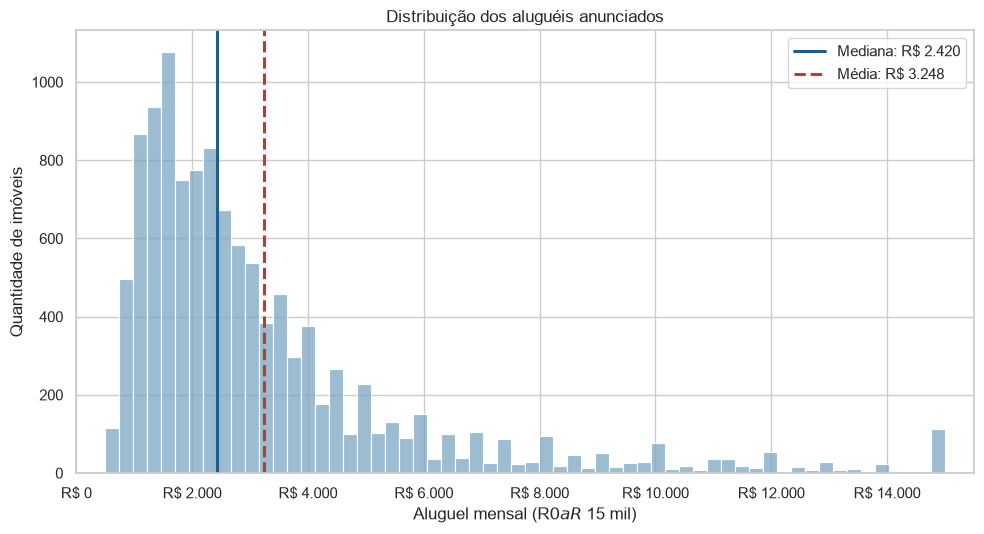

In [4]:
media, mediana = df["rent"].mean(), df["rent"].median()
resumo_precos = pd.DataFrame({
    "aluguel (bruta)": bruto["rent"].describe(),
    "aluguel (limpa)": df["rent"].describe(),
    "total (limpa)": df["total"].describe(),
}).round(2)
print(resumo_precos)
print(f"\nA média fica {media - mediana:,.2f} reais ({(media / mediana - 1):.1%}) acima da mediana")

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.histplot(df["rent"], bins=60, color="#7aa6c2", ax=ax)
ax.axvline(mediana, color="#1f5f8b", lw=2.2, label=f"Mediana: R$ {mediana:,.0f}".replace(",", "."))
ax.axvline(media, color="#c0392b", lw=2.2, ls="--", label=f"Média: R$ {media:,.0f}".replace(",", "."))
ax.set_xlim(0, 15500)
ax.xaxis.set_major_formatter(reais)
ax.set_title("Distribuição dos aluguéis anunciados")
ax.set_xlabel("Aluguel mensal (R$ 0 a R$ 15 mil)")
ax.set_ylabel("Quantidade de imóveis")
ax.legend()
salvar(fig, "01_distribuicao_media_mediana.png")

## 4. Bairros mais caros e mais baratos (mínimo de 30 anúncios)

Bairros com 30 anúncios ou mais: 78 de 1198

Mais caros:
                      anuncios  aluguel_medio  aluguel_mediano  area_mediana  \
district                                                                      
Jardim Leonor              38        7455.74           7428.0         167.5   
Tamboré                    34        6912.68           6550.0         113.0   
Cerqueira César           140        6750.66           5925.0          92.0   
Jardim Paulista           220        6305.96           5000.0          90.0   
Paraíso                    89        6285.56           4571.0          96.0   
Vila Nova Conceição        77        6246.77           4850.0          70.0   
Itaim Bibi                 51        6105.29           5000.0          70.0   
Brooklin Paulista          46        6074.67           4550.0         114.0   
Cidade Monções             49        6034.27           4500.0          65.0   
Vila Madalena              32        5835.31           4125.0          71

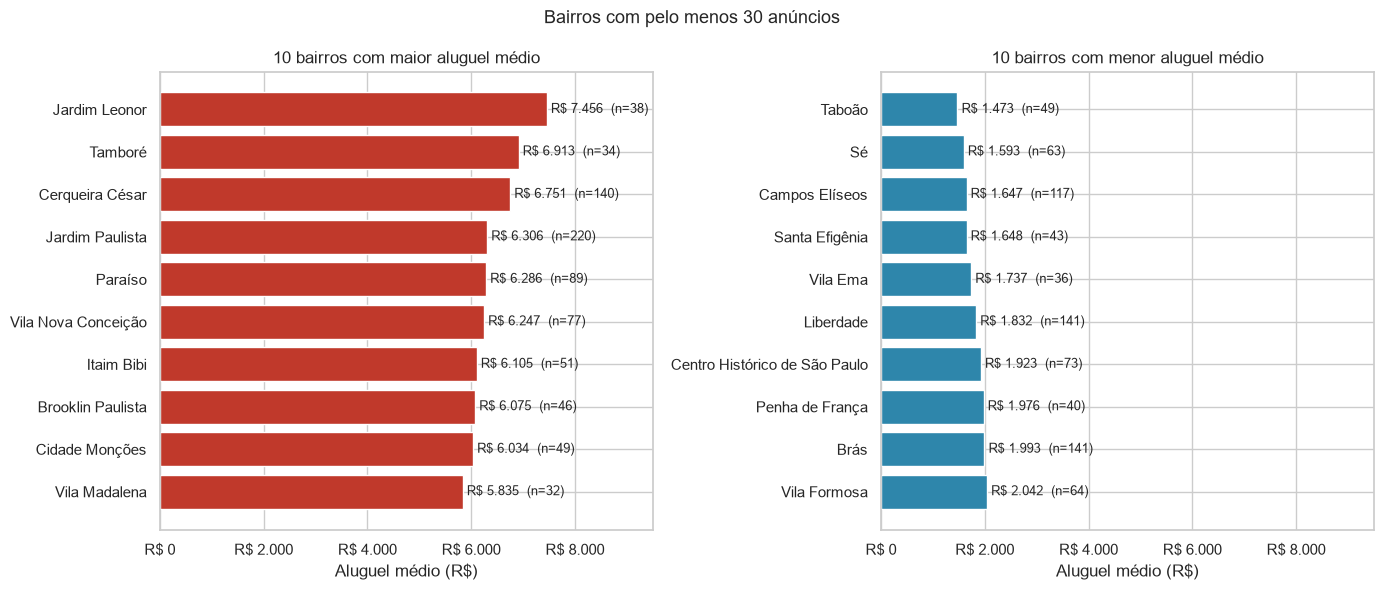

In [5]:
bairros = (df.groupby("district")
             .agg(anuncios=("rent", "size"),
                  aluguel_medio=("rent", "mean"),
                  aluguel_mediano=("rent", "median"),
                  area_mediana=("area", "median"),
                  m2_mediano=("preco_m2", "median"))
             .query("anuncios >= 30")
             .round(2))
caros = bairros.sort_values("aluguel_medio", ascending=False).head(10)
baratos = bairros.sort_values("aluguel_medio").head(10)
print("Bairros com 30 anúncios ou mais:", len(bairros), "de", df["district"].nunique())
print("\nMais caros:\n", caros)
print("\nMais baratos:\n", baratos)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, dados, cor, titulo in [(a1, caros, "#c0392b", "10 bairros com maior aluguel médio"),
                               (a2, baratos, "#2e86ab", "10 bairros com menor aluguel médio")]:
    dados = dados.iloc[::-1]
    ax.barh(dados.index, dados["aluguel_medio"], color=cor)
    for i, (v, n) in enumerate(zip(dados["aluguel_medio"], dados["anuncios"])):
        ax.text(v + 80, i, f"R$ {v:,.0f}  (n={n})".replace(",", "."), va="center", fontsize=9)
    ax.set_title(titulo)
    ax.set_xlabel("Aluguel médio (R$)")
    ax.xaxis.set_major_formatter(reais)
a1.set_xlim(0, 9500)
fig.suptitle("Bairros com pelo menos 30 anúncios", fontsize=13)
salvar(fig, "02_top10_bairros_caros_baratos.png")

## 5. Aluguel x características do imóvel

Correlação com o aluguel (Pearson):
area        0.671
bedrooms    0.537
garage      0.620
rent        1.000
Name: rent, dtype: float64


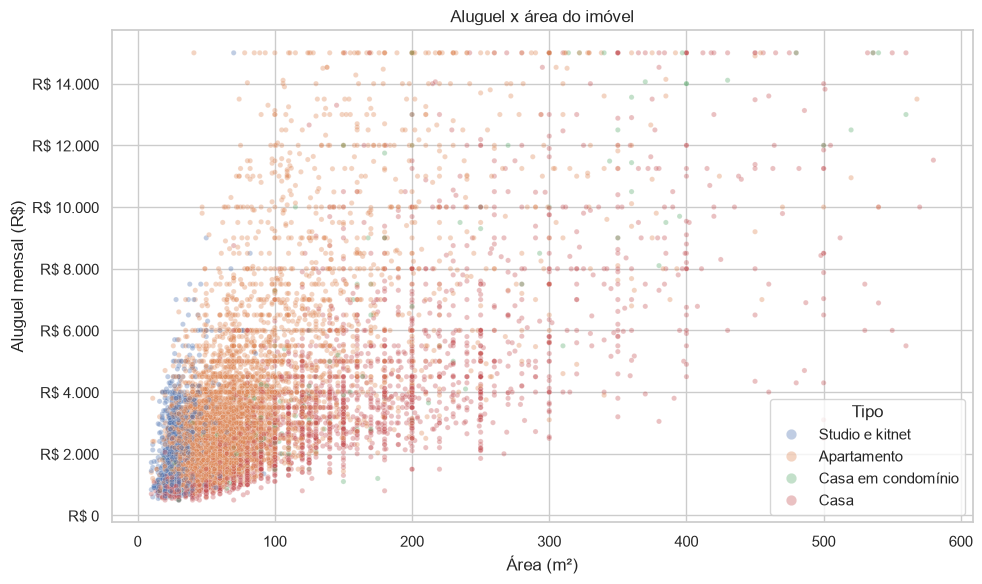

In [6]:
colunas = ["area", "bedrooms", "garage", "rent"]
print("Correlação com o aluguel (Pearson):")
print(df[colunas].corr()["rent"].round(3))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="area", y="rent", hue="type", alpha=0.35, s=14, ax=ax)
ax.yaxis.set_major_formatter(reais)
ax.set_title("Aluguel x área do imóvel")
ax.set_xlabel("Área (m²)")
ax.set_ylabel("Aluguel mensal (R$)")
ax.legend(title="Tipo", markerscale=2)
salvar(fig, "03_aluguel_vs_area.png")

          anuncios  area_media  aluguel_medio  aluguel_mediano
bedrooms                                                      
0               26       30.88        1541.96           1253.5
1             4184       40.67        2144.84           1708.5
2             4343       70.55        2749.87           2200.0
3             2422      138.70        4795.90           3800.0
4              542      249.83        7804.99           7115.0
5               91      322.68        8568.25           8000.0
6               23      331.39        8346.30           8000.0
        anuncios  aluguel_mediano
garage                           
0           4105           1530.0
1           4568           2446.0
2           1904           3940.0
3            537           6000.0
4            320           7428.0
5            112           8320.0
6             85           8430.0


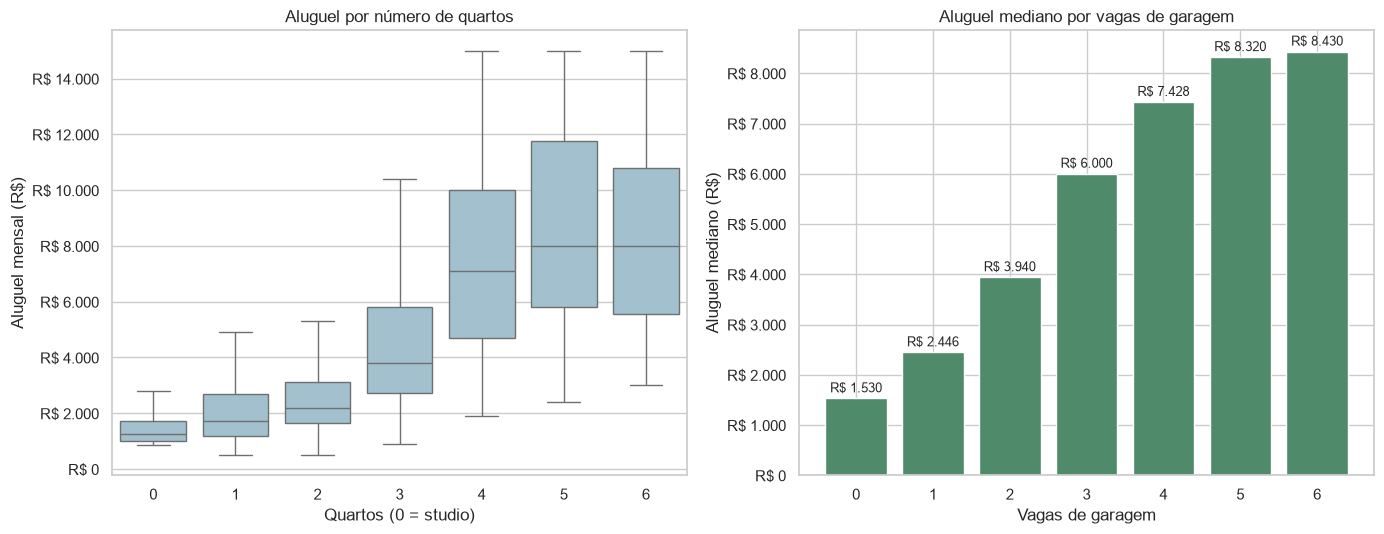

In [7]:
por_quartos = df.groupby("bedrooms").agg(anuncios=("rent", "size"), area_media=("area", "mean"),
                                         aluguel_medio=("rent", "mean"), aluguel_mediano=("rent", "median")).round(2)
por_vagas = df.groupby("garage").agg(anuncios=("rent", "size"), aluguel_mediano=("rent", "median")).round(2)
print(por_quartos)
print(por_vagas)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=df, x="bedrooms", y="rent", color="#9cc3d5", showfliers=False, ax=a1)
a1.set_title("Aluguel por número de quartos")
a1.set_xlabel("Quartos (0 = studio)")
a1.set_ylabel("Aluguel mensal (R$)")
a1.yaxis.set_major_formatter(reais)

a2.bar(por_vagas.index.astype(str), por_vagas["aluguel_mediano"], color="#4f8a6b")
for x, v in zip(por_vagas.index, por_vagas["aluguel_mediano"]):
    a2.text(x, v + 120, f"R$ {v:,.0f}".replace(",", "."), ha="center", fontsize=9)
a2.set_title("Aluguel mediano por vagas de garagem")
a2.set_xlabel("Vagas de garagem")
a2.set_ylabel("Aluguel mediano (R$)")
a2.yaxis.set_major_formatter(reais)
salvar(fig, "04_aluguel_por_quartos_e_vagas.png")

                    anuncios  aluguel_mediano  encargos_medianos  \
type                                                               
Studio e kitnet         1379           1846.0              487.0   
Casa em condomínio       239           2200.0              307.0   
Casa                    2831           2600.0              193.0   
Apartamento             7182           2500.0              776.0   

                    total_mediano  m2_mediano  
type                                           
Studio e kitnet            2318.0       61.11  
Casa em condomínio         2650.0       31.25  
Casa                       2842.0       24.67  
Apartamento                3296.0       41.60  


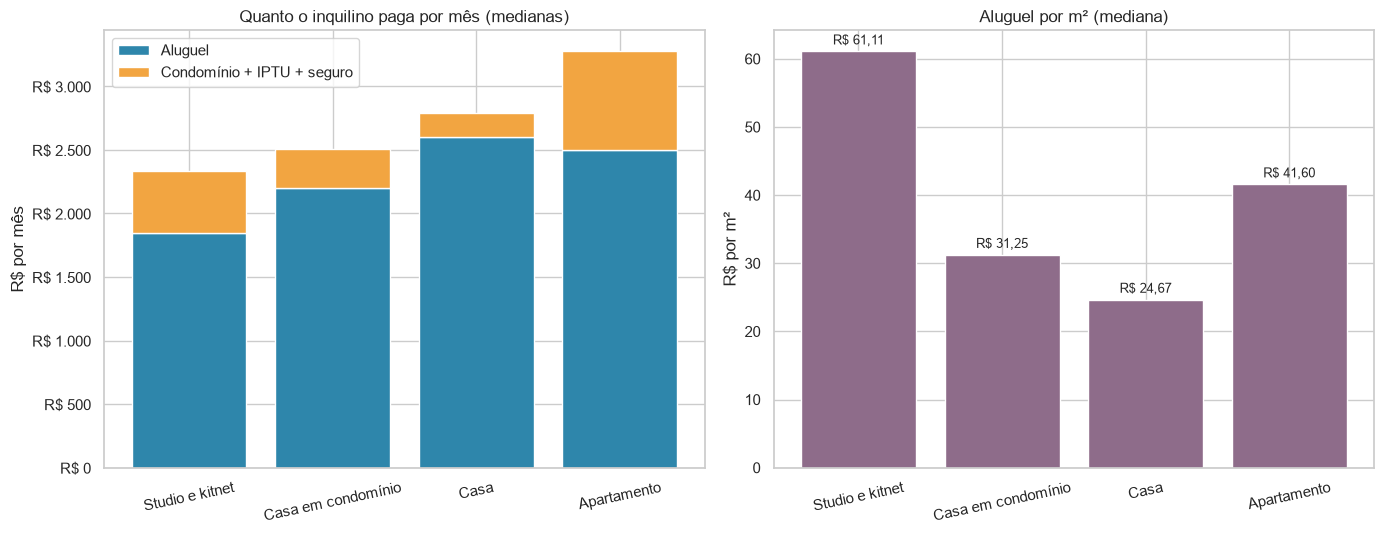

In [8]:
por_tipo = df.groupby("type").agg(anuncios=("rent", "size"), aluguel_mediano=("rent", "median"),
                                  encargos_medianos=("encargos", "median"), total_mediano=("total", "median"),
                                  m2_mediano=("preco_m2", "median")).round(2).sort_values("total_mediano")
print(por_tipo)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
a1.bar(por_tipo.index, por_tipo["aluguel_mediano"], color="#2e86ab", label="Aluguel")
a1.bar(por_tipo.index, por_tipo["encargos_medianos"], bottom=por_tipo["aluguel_mediano"],
       color="#f2a541", label="Condomínio + IPTU + seguro")
a1.set_title("Quanto o inquilino paga por mês (medianas)")
a1.set_ylabel("R$ por mês")
a1.yaxis.set_major_formatter(reais)
a1.legend()
a1.tick_params(axis="x", rotation=12)

a2.bar(por_tipo.index, por_tipo["m2_mediano"], color="#8e6c8a")
for i, v in enumerate(por_tipo["m2_mediano"]):
    a2.text(i, v + 1, f"R$ {v:.2f}".replace(".", ","), ha="center", fontsize=9)
a2.set_title("Aluguel por m² (mediana)")
a2.set_ylabel("R$ por m²")
a2.tick_params(axis="x", rotation=12)
salvar(fig, "05_custo_total_e_m2_por_tipo.png")

## 6. Exporta as tabelas

In [9]:
with pd.ExcelWriter("resultados/tabelas_resumo.xlsx") as xls:
    resumo_precos.to_excel(xls, sheet_name="media_mediana")
    caros.to_excel(xls, sheet_name="bairros_caros")
    baratos.to_excel(xls, sheet_name="bairros_baratos")
    por_quartos.to_excel(xls, sheet_name="quartos")
    por_vagas.to_excel(xls, sheet_name="vagas")
    por_tipo.to_excel(xls, sheet_name="tipo")
    df[colunas].corr().round(3).to_excel(xls, sheet_name="correlacao")
print("Tabelas salvas em resultados/tabelas_resumo.xlsx")

Tabelas salvas em resultados/tabelas_resumo.xlsx
